<a href="https://colab.research.google.com/github/Yiting-Wang98/MSSP607/blob/main/assignments/case%20study%20report%20assignments%202/case%20study%202.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt
from sklearn.linear_model import LinearRegression
from scipy import stats
from io import StringIO
import itertools
import os
import subprocess
from pathlib import Path

pd.set_eng_float_format(accuracy=3, use_eng_prefix=True)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

owner = 'Yiting-Wang98'
repository = 'MSSP607'
repo_url = f'https://github.com/Yiting-Wang98/MSSP607.git'
repo_path = Path('/content') / repository

if not repo_path.exists():
    subprocess.run(
        ['git', 'clone', repo_url, str(repo_path)],
        check=True
    )
else:
    print("Repository already exists. Using the existing copy.")

os.chdir(repo_path)

print("Current directory:", os.getcwd())

print("Files in repository:")
for item in sorted(repo_path.rglob('*')):
    if item.is_file() and '.git' not in item.parts:
        print(item.relative_to(repo_path))

Repository already exists. Using the existing copy.
Current directory: /content/MSSP607
Files in repository:
Adding_File_Structure.py
Modules/week 4/week 4module
Modules/week 6/week assignments6.ipynb
Modules/week 7/assignment_7.ipynb
Modules/week 7/week 7 assignment
Modules/week 8/week 8 assignment.ipynb
Modules/week1/Participation_Activity_Week1_Exercises.ipynb
Modules/week1/Week 1 Introduction_To_Data_Analysis (2).ipynb
Modules/week1/stats_viz.py
Modules/week2/Week 2 Data Stuctures.ipynb
Modules/week3/Week 3 Built In Data Structures Functions and Files.ipynb
Modules/week5/week5 module
assignment template.ipynb
assignments/case study report assignment 1/assignment 1.ipynb
assignments/case study report assignment 1/data_academic_performance (2).xlsx
assignments/case study report assignments 2/case study 2
assignments/week 3/week 3 assignment.ipynb
assignments/week 4/week 4 assignments.ipynb
assignments/week 5/InternetSales.csv
assignments/week 5/week_5_assignment.ipynb
assignments/wee

1. set precison of floating point for results and visualizations

In [2]:
import pandas as pd
import numpy as np
import sklearn as sk
from io import StringIO
import sys
import matplotlib as mpl
import matplotlib.pyplot as plt
%matplotlib inline
from datetime import date as dt
pd.set_eng_float_format(accuracy=3, use_eng_prefix=True)
pd.set_option('display.float_format', lambda x: '%.0f' % x) #

2. read the csv

In [3]:
sales=pd.read_csv('/content/MSSP607/data/week 7/InternetSales.csv',
                  parse_dates=['BirthDate','DateFirstPurchase','OrderDate','ShipDate'],
                  low_memory=False,
                  index_col=[0],
                  encoding='latin-1')
sales['BirthDate'].head(10)


,BirthDate
ID,
0,1971-10-06
1,1971-10-06
2,1971-10-06
3,1971-10-06
4,1971-10-06
5,1971-10-06
6,1971-10-06
7,1971-10-06
8,1976-05-10


3.check the dataset

In [4]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
Index: 60398 entries, 0 to 60397
Data columns (total 59 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   CustomerKey               60398 non-null  int64         
 1   GeographyKey              60398 non-null  int64         
 2   City                      60398 non-null  object        
 3   CountryRegionCode         60398 non-null  object        
 4   EnglishCountryRegionName  60398 non-null  object        
 5   CustomerAlternateKey      60398 non-null  object        
 6   Title                     307 non-null    object        
 7   FirstName                 60398 non-null  object        
 8   MiddleName                34903 non-null  object        
 9   LastName                  60398 non-null  object        
 10  NameStyle                 60398 non-null  bool          
 11  BirthDate                 60398 non-null  datetime64[ns]
 12  MaritalStatus          

In [5]:
sales.shape
sales.shape[0]
sales.shape[1]
sales.columns
sales.head(5)
sales.to_csv('/content/MSSP607/data/sales.csv',encoding='utf-8')



4.delete the null

In [6]:
dfsales=sales
dfsales.isnull().sum()
dfsales.shape


(60398, 59)

In [7]:
dfsales.dropna(axis=0)
dfsales.shape

(60398, 59)

In [8]:
dfsales=sales
dfsales.shape

(60398, 59)

In [9]:
dfsales1 = dfsales.dropna(axis=1)
print(dfsales1.shape)

(60398, 53)


In [10]:
dfsales1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 60398 entries, 0 to 60397
Data columns (total 53 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   CustomerKey               60398 non-null  int64         
 1   GeographyKey              60398 non-null  int64         
 2   City                      60398 non-null  object        
 3   CountryRegionCode         60398 non-null  object        
 4   EnglishCountryRegionName  60398 non-null  object        
 5   CustomerAlternateKey      60398 non-null  object        
 6   FirstName                 60398 non-null  object        
 7   LastName                  60398 non-null  object        
 8   NameStyle                 60398 non-null  bool          
 9   BirthDate                 60398 non-null  datetime64[ns]
 10  MaritalStatus             60398 non-null  object        
 11  Gender                    60398 non-null  object        
 12  EmailAddress           

4.

In [11]:
dfsales1 = dfsales1.assign(orderyear = dfsales1['OrderDate'].dt.year)
dfsales1 = dfsales1.assign(orderquarter = dfsales1['OrderDate'].dt.quarter)
dfsales1 = dfsales1.assign(ordermonth = dfsales1['OrderDate'].dt.month)
dfsales1 = dfsales1.assign(orderday = dfsales1['OrderDate'].dt.day)
dfsales1[['orderyear','orderquarter','ordermonth','orderday']].head(10)


,orderyear,orderquarter,ordermonth,orderday
ID,,,,
0,2011,1,1,19
1,2013,1,1,18
2,2013,1,1,18
3,2013,2,5,3
4,2013,2,5,3
5,2013,2,5,3
6,2013,2,5,3
7,2013,2,5,3
8,2013,1,1,16


In [12]:
dfsales1[['EnglishProductName','OrderQuantity','UnitPrice','ExtendedAmount',
         'UnitPriceDiscountPct','DiscountAmount','ProductStandardCost','TotalProductCost']].describe()

,OrderQuantity,UnitPrice,ExtendedAmount,UnitPriceDiscountPct,DiscountAmount,ProductStandardCost,TotalProductCost
count,60398,60398,60398,60398,60398,60398,60398
mean,1,486,486,0,0,286,286
std,0,928,928,0,0,552,552
min,1,2,2,0,0,1,1
25%,1,8,8,0,0,3,3
50%,1,30,30,0,0,11,11
75%,1,540,540,0,0,295,295
max,1,3578,3578,0,0,2171,2171


**A.What are the Internet sales of Adventure Works by year for each Country Region?**

In [13]:
dfsales1['Profit'] = dfsales1['SalesAmount'] - dfsales1['TotalProductCost']

In [14]:
grouped = dfsales1.groupby('CountryRegionCode')

In [15]:
pivot_total = dfsales1.pivot_table(index='orderyear', columns='EnglishCountryRegionName',
                                   values='SalesAmount', aggfunc='sum',
                                   margins=True, margins_name='Total').round(0)
pivot_total


EnglishCountryRegionName,Australia,Canada,France,Germany,United Kingdom,United States,Total
orderyear,,,,,,,
2010,20910,3578,3400,NaN,699,14834,43421
2011,2563732,571572,410845,520500,550591,2458285,7075526
2012,2128407,307605,648066,608658,712701,1437049,5842485
2013,4339443,1085633,1578512,1761876,2124007,5462079,16351550
2014,8508,9458,3195,3278,3714,17543,45695
Total,9061001,1977845,2644018,2894312,3391712,9389790,29358677


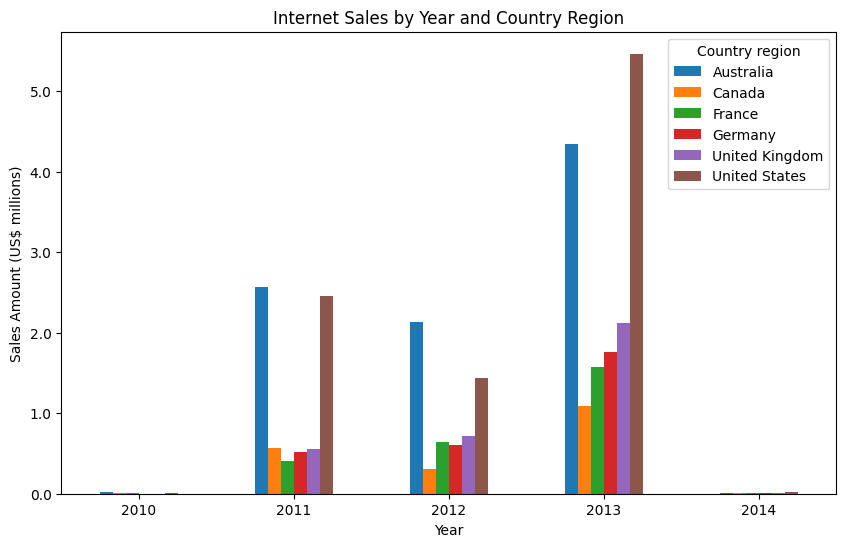

In [16]:
from matplotlib.ticker import FuncFormatter

pivot_plot = pivot_total.drop(index='Total', columns='Total')

ax = pivot_plot.plot(kind='bar', figsize=(10, 6))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v/1e6:.1f}'))
plt.title('Internet Sales by Year and Country Region')
plt.xlabel('Year'); plt.ylabel('Sales Amount (US$ millions)')
plt.legend(title='Country region')
plt.xticks(rotation=0)
plt.show()

In [17]:
dfsales1.groupby('orderyear').agg(order_lines=('SalesAmount','size'),
                                  first_order=('OrderDate','min'),
                                  last_order=('OrderDate','max'),
                                  months=('ordermonth','nunique'))


,order_lines,first_order,last_order,months
orderyear,,,,
2010,14,2010-12-29,2010-12-31,1
2011,2216,2011-01-01,2011-12-31,12
2012,3397,2012-01-01,2012-12-31,12
2013,52801,2013-01-01,2013-12-31,12
2014,1970,2014-01-01,2014-01-28,1


**B.Generate summary statistics including min, max, and standard deviation for Yearly Income, Gender by Country Regions.**

In [18]:
customer=dfsales1.drop_duplicates('CustomerKey')

In [19]:
income = (customer
          .groupby(['CountryRegionCode', 'Gender'])['YearlyIncome']
          .agg(['min', 'max', 'std'])
          .round(0))
income

min     max   std
CountryRegionCode Gender                     
AU                F       10000  160000 31164
                  M       10000  170000 32451
CA                F       10000  170000 19182
                  M       10000  170000 21215
DE                F       10000  130000 35716
                  M       10000  130000 35277
FR                F       10000  110000 26916
                  M       10000  110000 27633
GB                F       10000  170000 48288
                  M       10000  170000 48593
US                F       10000  170000 25167
                  M       10000  170000 26228

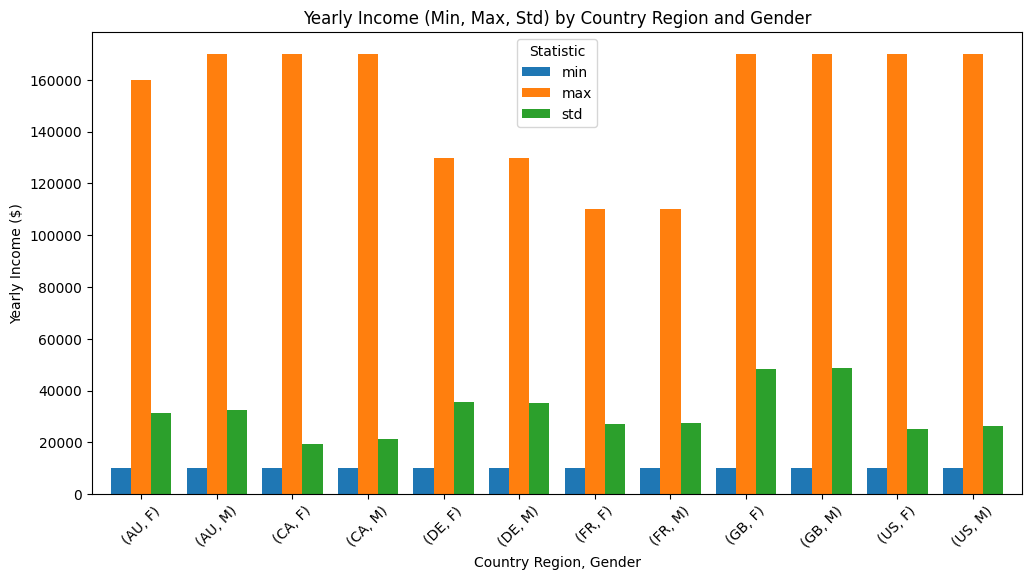

In [20]:
income.plot(kind='bar', figsize=(12, 6), width=0.8)
plt.title('Yearly Income (Min, Max, Std) by Country Region and Gender')
plt.xlabel('Country Region, Gender'); plt.ylabel('Yearly Income ($)')
plt.xticks(rotation=45)
plt.legend(title='Statistic')
plt.show()

**C.What is the average price of the product category that generates the most sales?**

In [21]:
def category(name):
    n = name.lower()
    if n.startswith(("mountain-", "road-", "touring-")) and "tire" not in n and "bottle" not in n:
        return "Bikes"
    if any(k in n for k in ["cap", "jersey", "gloves", "vest", "shorts", "socks"]):
        return "Clothing"
    return "Accessories"

dfsales1['Category'] = dfsales1['EnglishProductName'].apply(category)

Sales by Year and Product Category

In [22]:
dfsales1.pivot_table(index='orderyear', columns='Category',
                     values='SalesAmount', aggfunc='sum',
                     fill_value=0, margins=True, margins_name='Total')

Category,Accessories,Bikes,Clothing,Total
orderyear,,,,
2010,0,43421,0,43421
2011,0,7075526,0,7075526
2012,2147,5839695,643,5842485
2013,668242,15359502,323806,16351550
2014,30371,0,15323,45695
Total,700760,28318145,339773,29358677


In [23]:
shares = dfsales1.groupby('Category').agg(sales=('SalesAmount', 'sum'),
                                      avg_unit_price=('UnitPrice', 'mean'))
shares['sales_share_%'] = shares['sales'] / shares['sales'].sum() * 100

with pd.option_context('display.float_format', '{:,.2f}'.format):
    print(shares.to_string())
    print('Median bike unit price:',
          dfsales1.loc[dfsales1['Category'] == 'Bikes', 'UnitPrice'].median())

                    sales  avg_unit_price  sales_share_%
Category                                                
Accessories    700,759.96           19.42           2.39
Bikes       28,318,144.65        1,862.42          96.46
Clothing       339,772.61           37.33           1.16
Median bike unit price: 2071.4196


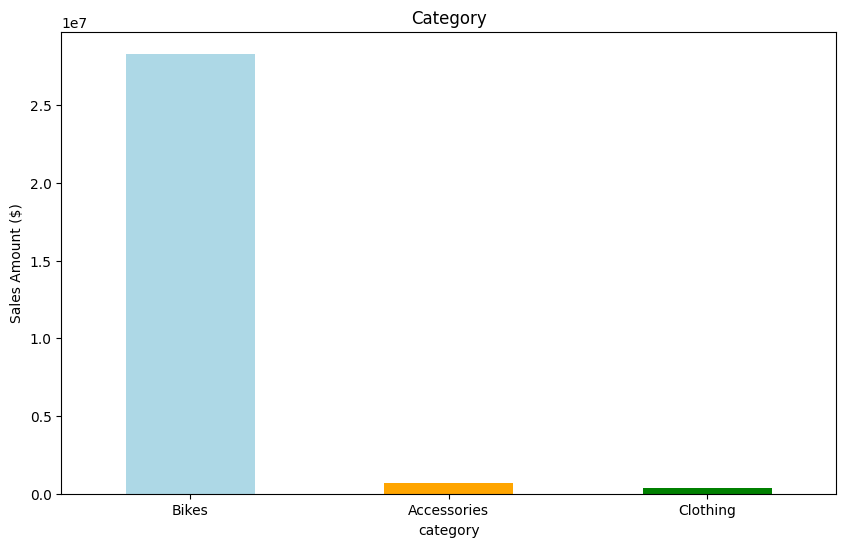

In [24]:
most_sales=(dfsales1.groupby('Category')['SalesAmount'].sum().sort_values(ascending=False))
most_sales.plot(kind='bar', figsize=(10, 6),color=['lightblue', 'orange', 'green'])
plt.title('Category')
plt.xlabel('category'); plt.ylabel('Sales Amount ($)')
plt.xticks(rotation=0)
plt.show()

In [25]:
dfsales1.groupby('Category')['UnitPrice'].agg(['mean', 'median']).round(2)

,mean,median
Category,,
Accessories,19,10
Bikes,1862,2071
Clothing,37,50


**D.Does owning a home make a difference in sales? Explain your analysis.**

In [26]:
customer_owinghome = (dfsales1
        .groupby(['CustomerKey', 'HouseOwnerFlag'])['SalesAmount']
        .sum()
        .reset_index())

In [27]:
summary = customer_owinghome.groupby('HouseOwnerFlag')['SalesAmount'].agg(
    customers='count', mean='mean', median='median', std='std')
summary.round(1)

,customers,mean,median,std
HouseOwnerFlag,,,,
0,5982,1500,210,2047
1,12502,1631,342,2159


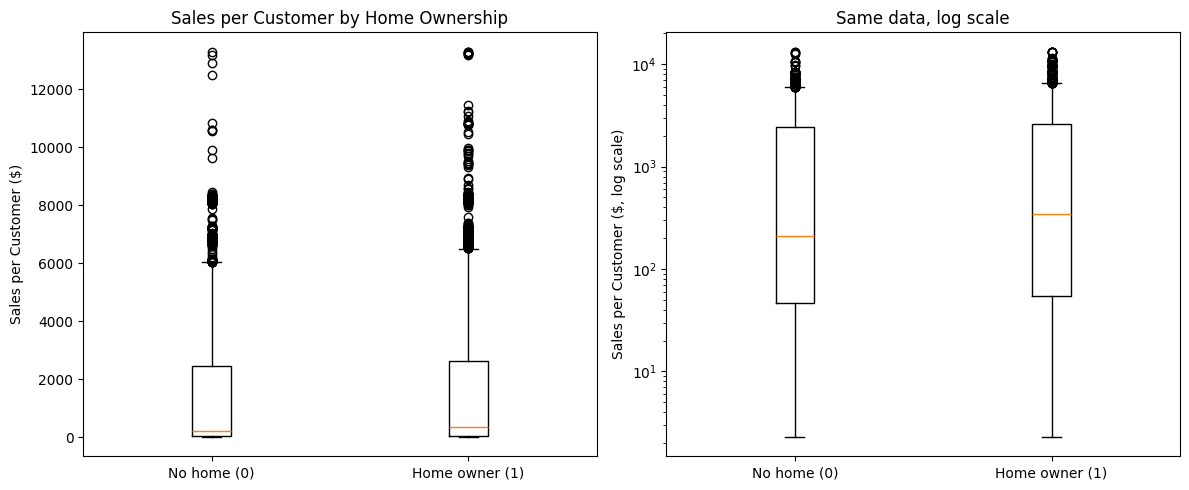

In [28]:
import matplotlib.pyplot as plt

data = [customer_owinghome[customer_owinghome['HouseOwnerFlag'] == 0]['SalesAmount'],
        customer_owinghome[customer_owinghome['HouseOwnerFlag'] == 1]['SalesAmount']]

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].boxplot(data, tick_labels=['No home (0)', 'Home owner (1)'])
ax[0].set_title('Sales per Customer by Home Ownership')
ax[0].set_ylabel('Sales per Customer ($)')

ax[1].boxplot(data, tick_labels=['No home (0)', 'Home owner (1)'])
ax[1].set_yscale('log')
ax[1].set_title('Same data, log scale')
ax[1].set_ylabel('Sales per Customer ($, log scale)')

plt.tight_layout()
plt.show()

In [29]:
customer_owinghome['HouseOwnerFlag'].corr(customer_owinghome['SalesAmount'])


np.float64(0.028746070546104077)

In [30]:
customer_owinghome.groupby('HouseOwnerFlag')['SalesAmount'].describe(percentiles=[.25, .5, .75])
print(customer_owinghome.groupby('HouseOwnerFlag')['SalesAmount'].describe(percentiles=[.25, .5, .75]))
print((customer_owinghome['SalesAmount'] > 6000).mean() * 100)

                count  mean  std  min  25%  50%  75%   max
HouseOwnerFlag                                            
0                5982  1500 2047    2   46  210 2443 13266
1               12502  1631 2159    2   54  342 2636 13295
5.2964726249729495


In [31]:
import statsmodels.formula.api as smf
model = smf.ols('SalesAmount ~ HouseOwnerFlag', data=customer_owinghome).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            SalesAmount   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                  0.001
Method:                 Least Squares   F-statistic:                     15.28
Date:                Thu, 29 Oct 2026   Prob (F-statistic):           9.28e-05
Time:                        02:14:23   Log-Likelihood:            -1.6783e+05
No. Observations:               18484   AIC:                         3.357e+05
Df Residuals:                   18482   BIC:                         3.357e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept       1500.0547     27.454     54.

In [32]:
share_owinghome = customer_owinghome.groupby('HouseOwnerFlag')['SalesAmount'].agg(
    customers='count', total_sales='sum')
share_owinghome['customers_share_%'] = share_owinghome['customers'] / share_owinghome['customers'].sum() * 100
share_owinghome['sales_share_%']     = share_owinghome['total_sales'] / share_owinghome['total_sales'].sum() * 100

with pd.option_context('display.float_format', '{:,.1f}'.format):
    print(share_owinghome.to_string())

                customers  total_sales  customers_share_%  sales_share_%
HouseOwnerFlag                                                          
0                    5982  8,973,327.4               32.4           30.6
1                   12502 20,385,349.8               67.6           69.4


In [33]:
share = customer_owinghome.groupby('HouseOwnerFlag')['SalesAmount'].agg(['count', 'sum'])  # 按是否有房统计客户数和总销售额
(share / share.sum() * 100).round(1)

,count,sum
HouseOwnerFlag,,
0,32,31
1,68,69


**E.Which product category has the highest profit and profit margin?**

In [34]:
category = dfsales1.groupby('Category').agg(
    sales=('SalesAmount', 'sum'),
    profit=('Profit', 'sum'),
    order_lines=('SalesAmount', 'size'))
category['margin_%']        = category['profit'] / category['sales']        * 100
category['profit_share_%']  = category['profit'] / category['profit'].sum() * 100
category['profit_per_line'] = category['profit'] / category['order_lines']

with pd.option_context('display.float_format', '{:,.2f}'.format):
    print(category.to_string())
    print('Total profit:', category['profit'].sum())

                    sales        profit  order_lines  margin_%  profit_share_%  profit_per_line
Category                                                                                       
Accessories    700,759.96    438,674.57        36092     62.60            3.63            12.15
Bikes       28,318,144.65 11,505,796.50        15205     40.63           95.24           756.71
Clothing       339,772.61    136,412.58         9101     40.15            1.13            14.99
Total profit: 12080883.645000001


In [35]:
   ctry = dfsales1.groupby('EnglishCountryRegionName').agg(
       customers=('CustomerKey', 'nunique'), sales=('SalesAmount', 'sum'), profit=('Profit', 'sum'))
   ctry['sales_per_customer'] = ctry['sales'] / ctry['customers']
   ctry['profit_share_%'] = ctry['profit'] / ctry['profit'].sum() * 100

In [36]:
bikes = dfsales1[dfsales1['Category'] == 'Bikes'].copy()
bikes['BikeType'] = bikes['EnglishProductName'].str.split('-').str[0]
bt = bikes.groupby('BikeType').agg(sales=('SalesAmount', 'sum'),
                                   profit=('Profit', 'sum'), units=('Profit', 'size'))
bt['margin_%'] = bt['profit'] / bt['sales'] * 100
bt['profit_per_unit'] = bt['profit'] / bt['units']

cats = dfsales1.groupby('CustomerKey')['Category'].agg(set)
has_bike  = cats.apply(lambda s: 'Bikes' in s)
has_other = cats.apply(lambda s: bool(s & {'Accessories', 'Clothing'}))
mix = pd.Series({'customers': len(cats),
                 'bought a bike': has_bike.sum(),
                 'bike + acc/clothing': (has_bike & has_other).sum(),
                 'acc/clothing only': (~has_bike & has_other).sum()})
mix['bike buyers who also bought acc/clothing_%'] = mix['bike + acc/clothing'] / mix['bought a bike'] * 100
mix['acc/clothing only_%'] = mix['acc/clothing only'] / mix['customers'] * 100


with pd.option_context('display.float_format', '{:,.1f}'.format):
    print(bt.to_string()); print(mix.to_string()); print(ctry.to_string())

                sales      profit  units  margin_%  profit_per_unit
BikeType                                                           
Mountain  9,952,759.6 4,513,624.1   4970      45.4            908.2
Road     14,520,584.0 5,537,299.7   8068      38.1            686.3
Touring   3,844,801.1 1,454,872.7   2167      37.8            671.4
customers                                    18,484.0
bought a bike                                 9,132.0
bike + acc/clothing                           7,677.0
acc/clothing only                             9,352.0
bike buyers who also bought acc/clothing_%       84.1
acc/clothing only_%                              50.6
                          customers       sales      profit  sales_per_customer  profit_share_%
EnglishCountryRegionName                                                                       
Australia                      3591 9,061,000.6 3,685,855.1             2,523.3            30.5
Canada                         1571 1,977,844.9 

In [37]:
dfsales1.groupby('Category')['Profit'].mean().round(0)

,Profit
Category,
Accessories,12
Bikes,757
Clothing,15


In [38]:
total_spend = dfsales1.groupby('CustomerKey')['SalesAmount'].sum()
print('Bike buyers, avg total spend:', round(total_spend[has_bike].mean(), 0))
print('Accessories/clothing-only, avg total spend:', round(total_spend[~has_bike].mean(), 0))

print(dfsales1.groupby('Category')['OrderDate'].agg(['min', 'max']))
first_year = dfsales1.groupby('CustomerKey')['OrderDate'].min().dt.year
print(first_year[~has_bike].value_counts().sort_index())

Bike buyers, avg total spend: 3146.0
Accessories/clothing-only, avg total spend: 68.0
                   min        max
Category                         
Accessories 2012-12-28 2014-01-28
Bikes       2010-12-29 2013-12-28
Clothing    2012-12-28 2014-01-28
OrderDate
2013    8846
2014     506
Name: count, dtype: int64
